# Stage 5 (part 1) — Deep time-series models: data preparation, TSMixer, TiDE

| Part | Prompt | Code |
|---|---|---|
| 1 | 5.1 data preparation for deep models | `src/deep_ts.py`, `tests/test_deep_ts.py` |
| 2 | 5.2 TSMixer | `deep_ts.run("tsmixer", …)` |
| 3 | 5.3 TiDE | `deep_ts.run("tide", …)` |

**Library (rule 13).** Checked on this machine: none of darts / neuralforecast / pytorch-forecasting was installed; all three are on
PyPI. **Chosen: darts 0.48.0** (with PyTorch Lightning 2.6.6, PyTorch 2.14.1), because (i) it has TSMixer, TiDE *and* TFT (part 2)
behind one API, (ii) it separates **past** and **known-future** covariates explicitly, and (iii) `historical_forecasts(retrain=False,
forecast_horizon=1)` produces one-step forecasts for every validation day from the *observed* lookback window — exactly the protocol
we need and can test. neuralforecast is designed around many series at once (panel data); pytorch-forecasting has no TSMixer.
API details (constructor arguments, `fit(val_series=…, load_best=…)`, `historical_forecasts` arguments, TiDE's
`temporal_width_*`) were read from the installed source/docstrings before writing code.

**Split:** the single deep-learning split of `src/splits.py` — training targets 1981-01-01 … 2014-12-30 (1-day purge), validation
targets 2015-01-01 … 2019-12-31. **The test years are never loaded** (`load_daily` stops at 2019-12-31).

### Step 1 — Setup

**WHAT:** imports and versions; quiet PyTorch-Lightning logging.

**Look for:** darts 0.48.0, CPU only.

In [1]:
import sys, json, subprocess, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, darts, pytorch_lightning

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import deep_ts as D, experiment as E

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
torch.set_num_threads(4)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
print("darts", darts.__version__, "| pytorch_lightning", pytorch_lightning.__version__, "| torch", torch.__version__,
      "| CUDA:", torch.cuda.is_available())

darts 0.48.0 | pytorch_lightning 2.6.6 | torch 2.14.1+cu130 | CUDA: False


**Interpretation:** darts 0.48.0, PyTorch Lightning 2.6.6 and PyTorch 2.14.1 run on the CPU (no GPU; the repeated `pin_memory` warnings
in later cells only say that no accelerator is present).

**Decision:** versions pinned in `requirements.txt`.

**Paper note:** *Deep forecasting models were implemented with Darts 0.48.0 on top of PyTorch 2.14.1 and PyTorch Lightning 2.6.6.*

# Part 1 — Prompt 5.1: data preparation

### Step 2 — Target, past covariates and known-future covariates

**WHAT:** build three daily series from `clean_daily.parquet` (truncated at 2019-12-31):
- **target:** `PRECTOTCORR` in mm, or `log(1 + mm)`;
- **past covariates** (known only up to day t): the nine other Set-B weather variables (QV2M, RH2M, T2M, T2M_MAX, T2M_MIN, T2MDEW,
  PS, WS2M, WS10M). The target's own history is an input automatically;
- **known-future covariates** (known for day t+1 already on day t): day-of-year sin/cos, harmonics 1 and 2.

**WHY:** deep sequence models learn their own "lags" and "rolling means" from the raw sequence, so they receive raw daily variables
instead of the 115 engineered columns. The calendar of tomorrow is genuinely known today, so it may enter as a future covariate; tomorrow's
weather is not, so weather variables are *past* covariates only (rule 5).

**Alternatives considered:** feeding the engineered Set-B table — would duplicate what the network should learn and blur the
comparison "feature engineering vs representation learning".

**Look for:** dates end on 2019-12-31; 9 past and 4 future columns.

In [2]:
df, fut = D.load_daily()
print("rows:", len(df), "|", df.index.min().date(), "->", df.index.max().date())
print("target:", D.TARGET, "| past covariates:", D.PAST, "| future covariates:", D.FUTURE)
display(df.tail(3)); fut.tail(3)

rows: 14244 | 1981-01-01 -> 2019-12-31
target: PRECTOTCORR | past covariates: ['QV2M', 'RH2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'T2MDEW', 'PS', 'WS2M', 'WS10M'] | future covariates: ['doy_sin1', 'doy_cos1', 'doy_sin2', 'doy_cos2']


,PRECTOTCORR,QV2M,RH2M,T2M,T2M_MAX,T2M_MIN,T2MDEW,PS,WS2M,WS10M
date,,,,,,,,,,
2019-12-29,0.0,8.92,74.88,16.85,23.22,11.10,12.18,100.38,1.68,2.96
2019-12-30,0.0,8.87,72.69,17.29,23.44,12.10,12.15,100.48,2.03,3.45
2019-12-31,0.0,10.11,74.77,18.93,24.19,13.63,14.17,100.55,1.53,2.75


,doy_sin1,doy_cos1,doy_sin2,doy_cos2
date,,,,
2019-12-29,-0.039,0.999,-0.077,0.997
2019-12-30,-0.022,1.000,-0.043,0.999
2019-12-31,-0.004,1.000,-0.009,1.000


**Interpretation:** 14,244 daily rows from 1981-01-01 to **2019-12-31** — the test years are not in memory. The target is rainfall; the nine
past covariates and four calendar covariates are as intended (the calendar values on 31 Dec are ≈ (0, 1, 0, 1), i.e. the annual cycle closes).

**Decision:** this is the complete input set for both deep models.

**Paper note:** *The deep models received daily rainfall as target, nine near-surface meteorological variables as past covariates and
day-of-year harmonics as known-future covariates.*

### Step 3 — Scalers fitted on training data only

**WHAT:** `deep_ts.prepare(transform, last_train)` standardises the target and the past covariates with darts `Scaler(StandardScaler())`
**fitted only on rows ≤ last_train** (2011-12-30 for the inner fit, 2014-12-30 for the refit), then transforms the whole series.
Sin/cos are already in [−1, 1] and are not scaled.

**WHY:** rule 6. Fitting on all years would leak the 2015–2019 mean and variance — which are very different after the 2016 jump —
into training.

**Look for:** the training mean of rainfall differs from the full-period mean, proving the scaler did not see validation years.

In [3]:
for transform in ("mm", "log"):
    d = D.prepare(transform, D.TRAIN_LAST)
    sc = d["y_scaler"]._fitted_params[0]
    raw = df[D.TARGET] if transform == "mm" else np.log1p(df[D.TARGET])
    print(f"{transform:3s}: scaler mean {sc.mean_[0]:.3f}, std {np.sqrt(sc.var_[0]):.3f} | training-rows mean "
          f"{raw.loc[:D.TRAIN_LAST].mean():.3f} | 2015-2019 mean {raw.loc[D.VAL_FIRST:].mean():.3f}")

mm : scaler mean 6.657, std 12.666 | training-rows mean 6.657 | 2015-2019 mean 14.421


log: scaler mean 1.134, std 1.270 | training-rows mean 1.134 | 2015-2019 mean 1.637


**Interpretation:** the scaler mean equals the training-rows mean exactly (6.657 mm; 1.134 on the log scale) and is far from the 2015–2019
mean (14.42 mm; 1.64): the scaler has not seen the validation years. Note how large the shift is — validation rainfall is **2.2×** the
training mean in mm (the 2016 regime). A model that partly predicts "towards the training mean" will be biased low.

**Decision:** scaling as implemented; keep an eye on bias.

**Paper note:** *All scalers were fitted on the training period only; validation-period rainfall was on average 2.2 times the training mean,
reflecting the documented inhomogeneity of the target.*

### Step 4 — How input windows of 14, 30 and 60 days are built

**WHAT:** for a forecast made at the end of day *t* (origin) for day *t+1*: the model sees the target and past covariates on days
*t−L+1 … t* and the calendar on days *t−L+1 … t+1*; output = rainfall on *t+1*. Training uses every such window whose output day lies
in the training period (≈ 12,000 windows, built internally by darts from the training series); validation forecasts are
made one day at a time with `historical_forecasts(retrain=False, forecast_horizon=1)`: each forecast is computed from the **true observed**
lookback window, never from the model's own earlier forecasts (no recursion), and the model is not retrained.

**WHY:** this mirrors the classical feature table (row t = information up to t, target t+1), so deep and classical results are comparable.

**Look for:** for origin 2016-07-15, the windows end on 2016-07-15 (target, past) and on 2016-07-16 (calendar only).

,target & past covariates,future covariates,forecast for
L = 14,2016-07-02 .. 2016-07-15,2016-07-02 .. 2016-07-16,2016-07-16
L = 30,2016-06-16 .. 2016-07-15,2016-06-16 .. 2016-07-16,2016-07-16
L = 60,2016-05-17 .. 2016-07-15,2016-05-17 .. 2016-07-16,2016-07-16


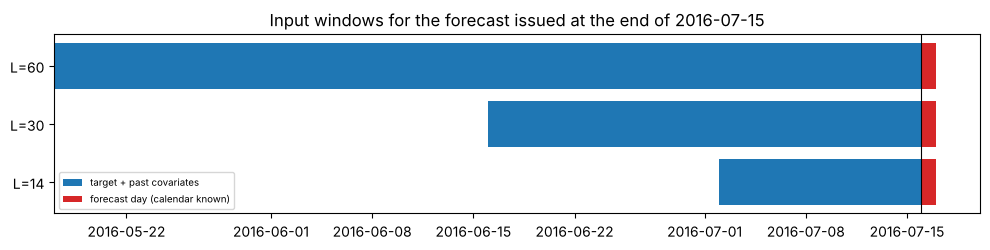

In [4]:
origin = pd.Timestamp("2016-07-15")
rows = {}
for L in D.LOOKBACKS:
    w = D.window(df, fut, origin, L)
    rows[f"L = {L}"] = {"target & past covariates": f"{w['target_and_past'].index.min().date()} .. {w['target_and_past'].index.max().date()}",
                        "future covariates": f"{w['future'].index.min().date()} .. {w['future'].index.max().date()}",
                        "forecast for": str(w["forecast_for"].date())}
display(pd.DataFrame(rows).T)

fig, ax = plt.subplots(figsize=(10, 2.6))
for i, L in enumerate(D.LOOKBACKS):
    lo = origin - pd.Timedelta(days=L - 1)
    ax.barh(i, (origin - lo).days + 1, left=lo, color="tab:blue", label="target + past covariates" if i == 0 else None)
    ax.barh(i, 1, left=origin + D.DAY, color="tab:red", label="forecast day (calendar known)" if i == 0 else None)
ax.set_yticks(range(3), [f"L={L}" for L in D.LOOKBACKS]); ax.axvline(origin + D.DAY, color="k", lw=0.8)
ax.set_title("Input windows for the forecast issued at the end of 2016-07-15"); ax.legend(fontsize=7, loc="lower left")
fig.tight_layout(); save(fig, "05_input_windows.png"); plt.show()

**Interpretation:** for the forecast issued at the end of 2016-07-15, the 14/30/60-day windows start on 07-02, 06-16 and 05-17 and all end on
07-15 for rain and weather; only the calendar reaches 07-16, the forecast day. This is the deep-learning equivalent of "row t uses information
≤ t" in the classical feature table.

**Decision:** windows as designed.

**Paper note:** *Each forecast used the preceding L ∈ {14, 30, 60} days of rainfall and meteorological variables and the calendar features
of the target day.*

### Step 5 — Automated proof: no window uses data after its origin, and validation forecasts use the observed lookback

**WHAT:** `tests/test_deep_ts.py` (7 tests): test years never loaded; windows end at the origin; scalers fitted on training rows only;
for 3 origins in 2016, the one-step validation forecast equals a forecast made with **all data after the origin physically removed**
(calendar only to origin + 1); and changing the *observed* rain on the origin day changes the forecast (inputs are observations,
not earlier predictions).

**WHY:** the truncation idea of Stage 2, applied to the deep pipeline: if any future value were used, removing it would change the forecast.

**Look for:** 7 passed.

In [5]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "-W", "ignore",
                    str(ROOT / "tests/test_deep_ts.py")], capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-400:], r.stderr[-300:])

.......                                                                  [100%]
7 passed in 7.55s
 


**Interpretation:** all **7 tests pass**. The key one: for three origins in 2016, the validation forecast is identical (to 1e-5) to a forecast
computed after **physically deleting every value after the origin** — so no window uses future data — and changing the observed rain on the
origin day changes the forecast — so each validation day is predicted from the true observed lookback, not recursively from earlier forecasts.

**Decision:** rules 4 and 5 verified for the deep pipeline.

**Paper note:** *Automated tests confirmed that each one-step-ahead validation forecast was invariant to the removal of all observations after
its forecast origin and depended on the observed (not previously predicted) values within the lookback window.*

# Part 2 — Prompt 5.2: TSMixer

### Step 6 — What TSMixer does, and how to describe it in a paper

TSMixer (Chen et al., 2023, *TSMixer: An All-MLP Architecture for Time Series Forecasting*) treats the input window as a small table:
**rows = time steps (L), columns = variables** (rain + 9 weather variables + 4 calendar features). It stacks *mixer blocks*, each with two MLPs:
- **time-mixing MLP:** applied to each variable separately *along the time axis* — it learns how the last L days of one variable combine
  (like learned lags, trends and moving averages);
- **feature-mixing MLP:** applied at each time step *across variables* — it learns how variables interact on the same day (e.g. humidity ×
  pressure × rain);
- residual connections and normalisation around both; a final projection maps to the forecast for day t+1.
In darts, past and known-future covariates are mixed in separately and combined before the blocks.

**Our configuration:** 2 mixer blocks, hidden size 32, feed-forward size 32, dropout 0.1, Adam (lr 1e-3, weight decay 1e-4), batch 256,
MSE loss on the scaled target, ≤ 60 epochs, early stopping (patience 8) on the slice 2012–2014, best weights restored → refit on
1981–2014 for the best number of epochs → one-step forecasts for 2015–2019. Lookbacks 14 / 30 / 60; targets mm and log(1 + mm)
(+ Duan smearing estimated on the slice; the naive `expm1` is reported too).

**Paper description (draft):** *TSMixer is an all-MLP architecture that alternates time-mixing layers, which share weights across
variables and model temporal dependencies within the input window, and feature-mixing layers, which share weights across time steps and
model cross-variable interactions; residual connections and normalisation are applied around each mixing layer.*

**Seeds:** 3 seeds (0–2) for all 6 configurations of each model (compute-limited CPU: TiDE takes ≈ 2.5 min per run), then seeds 3–4 are
added for the lookback selected per model and target, so headline configurations have **5 seeds** (playbook: 5 seeds, 3 if compute is tight).

**Look for (next step):** run times, best epochs.

In [6]:
REFS = D.dl_references()
SEEDS3 = [0, 1, 2]
def grid(kind, transforms=("mm", "log"), lookbacks=D.LOOKBACKS, seeds=SEEDS3):
    for transform in transforms:
        for L in lookbacks:
            for seed in seeds:
                out, info = D.run(kind, transform, L, seed)
                r = D.score_and_store(out, info, kind, transform, L, seed, REFS)
                mae = r[(r.metric == "MAE")].set_index("target")["value"].round(3).to_dict()
                print(f"{kind} {transform:3s} L={L:2d} seed {seed}: MAE {mae} | best epoch {info['best_epoch']} "
                      f"| smear {info['smear_factor']:.3f} | {info['fit_seconds']:.0f}s", flush=True)
t0 = time.time(); grid("tsmixer"); print(f"total {time.time() - t0:.0f}s")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


tsmixer mm  L=14 seed 0: MAE {'mm': 9.168} | best epoch 15 | smear nan | 26s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...

tsmixer log L=60 seed 1: MAE {'log_smear': 9.676, 'log_naive': 10.541} | best epoch 18 | smear 1.379 | 31s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


tsmixer log L=60 seed 2: MAE {'log_smear': 9.263, 'log_naive': 10.207} | best epoch 28 | smear 1.448 | 43s


total 635s


**Interpretation:** each TSMixer run (inner fit + refit + forecasts) takes 16–61 s; early stopping chooses 9–42 epochs. Smearing factors are
S ≈ 1.33–1.49 (slightly smaller than the boosters' 1.6). Seed-to-seed MAE differences reach 0.4 mm within one configuration (e.g. mm, L = 14:
8.83–9.24) — much larger than for the tree models.

**Decision:** report mean ± std over seeds.

**Paper note:** *TSMixer training converged within 9–42 epochs, with seed-to-seed MAE differences of up to 0.4 mm day⁻¹.*

### Step 7 — TSMixer results on the 2015–2019 validation period

**WHAT:** mean ± std over seeds of MAE, RMSE, bias, MSESS (vs climatology), MSESS vs seasonal + persistence, wet-day MAE and heavy-rain recall,
per lookback and target, next to the DL-split references (computed with the same `experiment.score`).

**WHY:** same metrics and references as Stages 3–4 (rule 7); the classical models will be scored on this split in 5.6.

**Look for:** the effect of lookback; mm vs log; the naive vs smeared log back-transform (Jensen again).

In [7]:
KEY = ["MAE", "RMSE", "bias", "MSESS", "MSESS_vs_seas_pers", "MAE_wet", "recall_ge20", "recall_ge50", "best_epoch"]
def summary(kind=None):
    r = pd.read_csv(D.RESULTS)
    r = r if kind is None else r[r.model == kind]
    g = r[r.metric.isin(KEY)].groupby(["model", "target", "lookback", "metric"])["value"]
    t = (g.mean().map("{:.3f}".format) + " ± " + g.std().fillna(0).map("{:.3f}".format)).unstack("metric")[KEY]
    t["n_seeds"] = r.groupby(["model", "target", "lookback"])["seed"].nunique()
    return t

def references_table():
    va, y, refs = REFS
    return pd.DataFrame({f"baseline:{k}": E.score("reg", y, refs[k], np.nan, refs, va)
                         for k in ("seasonal+persistence", "persistence", "climatology")}).T[KEY[:-1]].round(3)

tsm = summary("tsmixer"); tsm.to_csv(TAB / "05_tsmixer_validation.csv")
display(tsm); references_table()

metric                                 MAE            RMSE            bias          MSESS MSESS_vs_seas_pers         MAE_wet    recall_ge20    recall_ge50      best_epoch  n_seeds
model   target    lookback                                                                                                                                                         
tsmixer log_naive 14        10.120 ± 0.206  21.604 ± 0.402  -8.711 ± 0.426  0.125 ± 0.032     -0.331 ± 0.049  17.111 ± 0.413  0.152 ± 0.034  0.000 ± 0.000  32.000 ± 8.888        3
                  30        10.089 ± 0.297  21.572 ± 0.502  -8.523 ± 0.725  0.128 ± 0.041     -0.328 ± 0.062  17.050 ± 0.585  0.152 ± 0.035  0.000 ± 0.000  21.667 ± 2.517        3
                  60        10.229 ± 0.301  21.718 ± 0.681  -8.856 ± 0.580  0.116 ± 0.056     -0.346 ± 0.084  17.307 ± 0.600  0.150 ± 0.065  0.000 ± 0.000  25.333 ± 6.429        3
        log_smear 14         9.215 ± 0.112  19.425 ± 0.297  -5.987 ± 0.371  0.293 ± 0.022     -0.076 ± 0.033  15.039 ± 0.235  0.363 ± 0.039  0.053 ± 0.027  32.000 ± 8.888        3
                  30         9.230 ± 0.178  19.300 ± 0.537  -5.502 ± 1.046  0.302 ± 0.039     -0.063 ± 0.059  15.018 ± 0.401  0.398 ± 0.096  0.061 ± 0.045  21.667 ± 2.517        3
                  60         9.301 ± 0.358  19.433 ± 1.024  -5.964 ± 1.181  0.291 ± 0.075     -0.079 ± 0.114  15.153 ± 0.804  0.359 ± 0.102  0.068 ± 0.065  25.333 ± 6.429        3
        mm        14         9.078 ± 0.217  19.056 ± 0.428  -4.864 ± 0.520  0.319 ± 0.030     -0.036 ± 0.046  14.659 ± 0.313  0.467 ± 0.030  0.000 ± 0.000  21.667 ± 7.638        3
                  30         9.431 ± 0.156  19.548 ± 0.125  -5.573 ± 0.151  0.284 ± 0.009     -0.090 ± 0.014  15.162 ± 0.137  0.400 ± 0.017  0.000 ± 0.000  19.333 ± 5.508        3
                  60         9.492 ± 0.233  19.522 ± 0.142  -5.220 ± 0.278  0.286 ± 0.010     -0.087 ± 0.016  15.176 ± 0.069  0.421 ± 0.016  0.000 ± 0.000  17.667 ± 7.506        3

,MAE,RMSE,bias,MSESS,MSESS_vs_seas_pers,MAE_wet,recall_ge20,recall_ge50
baseline:seasonal+persistence,9.019,18.725,-4.595,0.343,0.000,14.585,0.459,0.152
baseline:persistence,9.663,19.967,0.000,0.253,-0.137,15.951,0.675,0.492
baseline:climatology,10.974,23.102,-7.766,0.000,-0.522,17.955,0.000,0.000


**Interpretation (validation 2015–2019, mean ± std over 3 seeds):**
- **TSMixer does not beat seasonal + persistence.** Best MAE: mm, L = 14, **9.08 ± 0.22** vs reference **9.02**; MSESS 0.32 vs 0.34
  (MSESS vs seasonal + persistence −0.04). Longer lookbacks are *worse* (L = 30/60: MAE 9.4–9.5).
- **Strong negative bias: −4.9 to −6.0 mm/day** (reference −4.6). TSMixer forecasts are pulled towards the training-period level and do not
  follow the post-2016 regime.
- **Jensen again:** log + naive `expm1` is very poor (MAE 10.1, bias −8.7, MSESS 0.12); smearing restores it (MAE 9.2, bias −6.0) but does not
  beat the mm target.
- Heavy rain: recall ≥ 50 mm is **0** for the mm target (forecasts never reach 50 mm), 0.05–0.07 with log + smearing; persistence reaches 0.49.

**Decision:** TSMixer is not competitive here; L = 14 is selected for both targets (Step 11).

**Paper note:** *TSMixer did not improve on the seasonal-persistence reference in the 2015–2019 validation period (MAE 9.1 vs 9.0 mm day⁻¹),
and longer input windows degraded its performance.*

### Step 8 — TSMixer training and validation loss curves

**WHAT:** for each lookback (log target, seed 0): (left) the **inner fit** — training loss and slice (2012–2014) loss per epoch, with the
early-stopping epoch; (right) the **refit** — training loss and the 2015–2019 validation loss, which is *only logged* (it decides nothing).

**WHY:** shows when the network starts to over-fit and whether the epoch chosen on the slice is also sensible on the later period.

**Look for:** the gap between training and validation loss; whether the 2015–2019 loss is still falling or already rising at the chosen epoch.

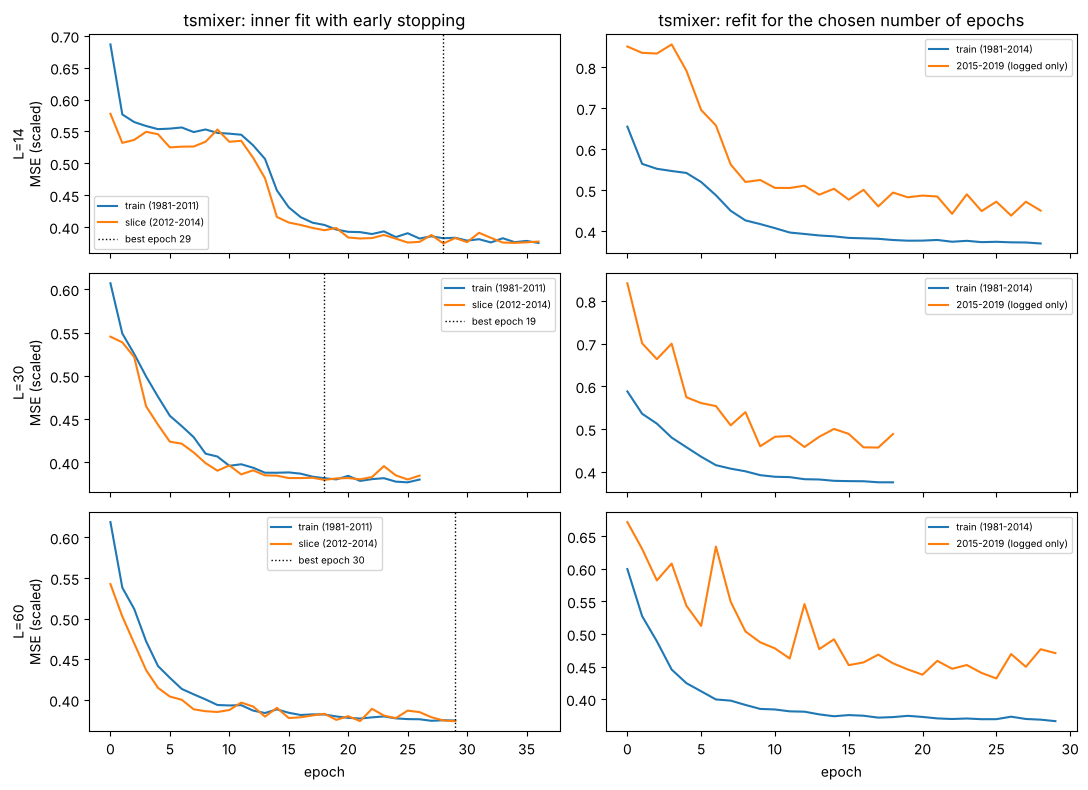

In [8]:
def curves(kind, transform="log", seed=0, name=None):
    fig, axes = plt.subplots(len(D.LOOKBACKS), 2, figsize=(11, 8), sharex="col")
    for i, L in enumerate(D.LOOKBACKS):
        h = json.loads((D.DEEP_DIR / f"{kind}_{transform}_L{L}__seed{seed}_history.json").read_text())
        a = axes[i, 0]; a.plot(h["inner_train"], label="train (1981-2011)"); a.plot(h["inner_val"], label="slice (2012-2014)")
        a.axvline(h["best_epoch"] - 1, color="k", ls=":", lw=1, label=f"best epoch {h['best_epoch']}")
        a.set(ylabel=f"L={L}\nMSE (scaled)"); a.legend(fontsize=7)
        b = axes[i, 1]; b.plot(h["refit_train"], label="train (1981-2014)"); b.plot(h["refit_val"], label="2015-2019 (logged only)")
        b.legend(fontsize=7)
    axes[0, 0].set_title(f"{kind}: inner fit with early stopping"); axes[0, 1].set_title(f"{kind}: refit for the chosen number of epochs")
    for a in axes[-1]: a.set_xlabel("epoch")
    fig.tight_layout(); save(fig, name or f"05_{kind}_loss_curves.png"); plt.show()
curves("tsmixer")

**Interpretation:**
- **Inner fit (left):** training and slice losses fall together and then flatten — the slice loss never rises sharply within 60 epochs, so this
  small, regularised network barely over-fits; early stopping mostly detects the plateau (L = 14 shows a long plateau followed by a sudden
  drop around epoch 12 — the optimiser escaping a poor solution, a typical non-convex behaviour and one reason seeds matter).
- **Refit (right):** the 2015–2019 loss (logged only) stays clearly **above** the training loss (≈ 0.45–0.50 vs 0.37) and is noisier: the gap is
  not memorisation but **distribution shift** — the validation years are much wetter than the training years.

**Decision:** the slice-based epoch choice is reasonable; the generalisation gap is a data-shift problem, not an over-fitting problem.

**Paper note:** *Learning curves showed little over-fitting within the training period, but a persistent gap between training and validation
loss consistent with the shift in rainfall regime after 2016.*

# Part 3 — Prompt 5.3: TiDE

### Step 9 — What TiDE does: a dense encoder–decoder with past and future covariates

TiDE (Das et al., 2023, *Long-term Forecasting with TiDE: Time-series Dense Encoder*) is built only from **residual MLP blocks**:
1. **feature projection:** past covariates of every day in the window are compressed by a small residual block (9 variables → 4 here);
   the known-future calendar features are used raw (`temporal_width_future=0`);
2. **dense encoder:** the flattened lookback (target history + projected past covariates + calendar of the window *and of the forecast day*)
   is encoded by residual blocks into one vector — a summary of "the state of the atmosphere over the last L days";
3. **dense decoder:** maps that vector to an output embedding for the forecast day;
4. **temporal decoder:** combines that embedding with the **known-future covariates of the forecast day** (the calendar of t+1) — the place
   where future information legitimately enters;
5. **global linear skip:** a linear map from the lookback directly to the forecast (a learned "AR" baseline the MLPs only need to correct).

**Past vs known-future covariates:** past covariates (weather) are only available up to day t, so they feed the encoder; future covariates
(calendar) are known for t+1, so they also feed the temporal decoder. Feeding tomorrow's *weather* as a future covariate would be leakage.

**Our configuration:** 1 encoder + 1 decoder layer, hidden size 64, decoder output dim 8, temporal decoder hidden 16, layer norm, dropout 0.1;
same optimiser, early stopping, refit, lookbacks, targets and seeds as TSMixer.

**Look for (next step):** run times (TiDE is slower), best epochs.

In [9]:
t0 = time.time(); grid("tide"); print(f"total {time.time() - t0:.0f}s")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


tide mm  L=14 seed 0: MAE {'mm': 9.866} | best epoch 9 | smear nan | 16s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...

tide log L=60 seed 1: MAE {'log_smear': 9.571, 'log_naive': 9.016} | best epoch 41 | smear 1.493 | 110s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


tide log L=60 seed 2: MAE {'log_smear': 9.65, 'log_naive': 9.018} | best epoch 32 | smear 1.506 | 73s


total 1002s


**Interpretation:** TiDE runs take 16–110 s; best epochs 9–56 (longer for the log target). Smearing factors are very stable (S ≈ 1.49–1.52).
Seed-to-seed variation is **small** (MAE within ≈ 0.1 mm for most configurations) — much more stable than TSMixer.

**Decision:** report mean ± std over seeds.

**Paper note:** *TiDE training was considerably more stable across random seeds than TSMixer.*

### Step 10 — TiDE results and loss curves

**WHAT:** the same table and curves as for TSMixer.

**Look for:** whether the encoder–decoder (and its use of the forecast-day calendar) changes anything relative to TSMixer.

metric                              MAE            RMSE            bias          MSESS MSESS_vs_seas_pers         MAE_wet    recall_ge20    recall_ge50       best_epoch  n_seeds
model target    lookback                                                                                                                                                         
tide  log_naive 14        9.194 ± 0.026  19.547 ± 0.089  -5.752 ± 0.148  0.284 ± 0.007     -0.090 ± 0.010  15.314 ± 0.046  0.451 ± 0.017  0.083 ± 0.008  44.667 ± 17.926        3
                30        9.099 ± 0.144  19.397 ± 0.405  -5.463 ± 0.644  0.295 ± 0.030     -0.073 ± 0.045  15.145 ± 0.250  0.478 ± 0.051  0.093 ± 0.042   29.333 ± 4.509        3
                60        9.033 ± 0.028  19.217 ± 0.091  -5.118 ± 0.137  0.308 ± 0.007     -0.053 ± 0.010  15.042 ± 0.050  0.518 ± 0.007  0.091 ± 0.008   35.000 ± 5.196        3
      log_smear 14        9.439 ± 0.059  17.922 ± 0.017  -0.715 ± 0.218  0.398 ± 0.001      0.084 ± 0.002  15.003 ± 0.102  0.723 ± 0.007  0.230 ± 0.009  44.667 ± 17.926        3
                30        9.473 ± 0.235  17.956 ± 0.037  -0.398 ± 1.001  0.396 ± 0.003      0.080 ± 0.004  15.075 ± 0.410  0.730 ± 0.024  0.275 ± 0.042   29.333 ± 4.509        3
                60        9.584 ± 0.060  18.000 ± 0.027   0.043 ± 0.202  0.393 ± 0.002      0.076 ± 0.003  15.300 ± 0.102  0.736 ± 0.003  0.285 ± 0.012   35.000 ± 5.196        3
      mm        14        9.861 ± 0.032  18.278 ± 0.033  -1.690 ± 0.113  0.374 ± 0.002      0.047 ± 0.003  14.844 ± 0.035  0.614 ± 0.001  0.212 ± 0.000  23.000 ± 12.288        3
                30        9.792 ± 0.025  18.116 ± 0.042  -1.067 ± 0.206  0.385 ± 0.003      0.064 ± 0.004  14.838 ± 0.050  0.670 ± 0.018  0.212 ± 0.008   19.667 ± 5.686        3
                60        9.863 ± 0.018  18.205 ± 0.087  -1.085 ± 0.407  0.379 ± 0.006      0.055 ± 0.009  14.909 ± 0.088  0.668 ± 0.017  0.207 ± 0.012   19.000 ± 4.359        3

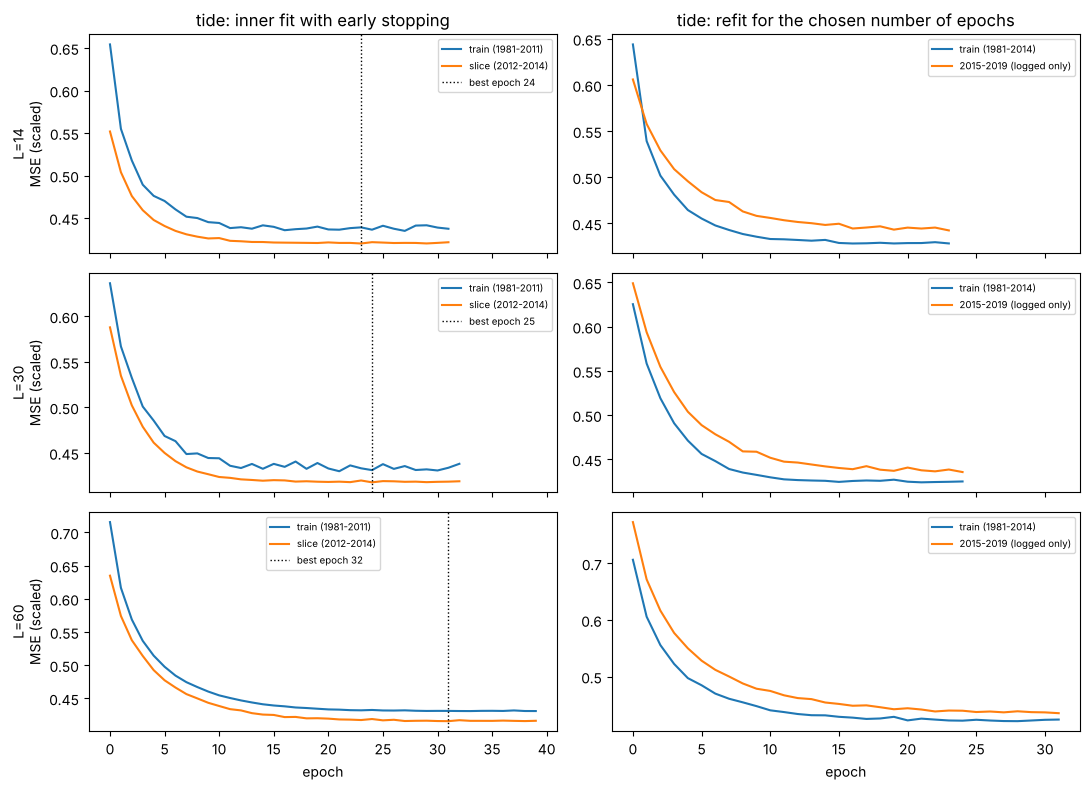

In [10]:
tide = summary("tide"); tide.to_csv(TAB / "05_tide_validation.csv")
display(tide)
curves("tide")

**Interpretation (validation 2015–2019):**
- **TiDE is the first model in this project that beats seasonal + persistence on squared error in the new regime:** log + smearing, L = 14:
  RMSE **17.92** vs 18.73, MSESS **0.398** vs 0.343 (**MSESS vs seasonal + persistence +0.084 ± 0.002**), bias only **−0.7 mm/day**, recall ≥ 20 mm
  **0.72** (reference 0.46) and ≥ 50 mm **0.23** (reference 0.15). The mm target behaves similarly (MSESS 0.385, bias −1.1).
- **But not on MAE:** 9.43 (log + smearing) / 9.79 (mm) vs 9.02. TiDE produces *mean-type* forecasts (it forecasts more rain on many days);
  the naive log variant is a *median-type* forecast with MAE 9.03–9.20 but bias −5.1 to −5.8. Same MAE–MSE trade-off as in Stage 4.
- **Why is TiDE's bias so much smaller than TSMixer's (−0.7 vs −6.0)?** TiDE has a **global linear skip connection** from the lookback window
  (including the target history) directly to the forecast. When the recent rain level is high (post-2016), the linear path carries it straight
  into the forecast — a learned, adaptive persistence. TSMixer's mixing layers instead regress towards levels typical of the training period.
- **Curves:** smooth; training loss *above* slice loss (dropout is active during training, and 2012–2014 is a relatively predictable period);
  slice loss flattens without rising — little over-fitting; the 2015–2019 loss tracks the training loss closely.
- Lookback hardly matters (MSESS 0.393–0.398 for log + smearing): consistent with the short memory found in Stage 1 (PACF ≈ 0 after lag 2).

**Decision:** TiDE (log + smearing) is the strongest deep model so far — on MSE, bias and heavy-rain recall, not on MAE. Whether it beats the
classical finalists will be decided in 5.6 on exactly this split.

**Paper note:** *TiDE with a log-transformed, smearing-corrected target improved on the seasonal-persistence reference in MSE skill
(+0.08) and reduced bias to −0.7 mm day⁻¹ in the 2015–2019 validation period, but did not improve MAE (9.4 vs 9.0 mm day⁻¹).*

### Step 11 — Five seeds for the selected lookback of each model and target

**WHAT:** for each model × target, select the lookback with the lowest mean validation **MAE** (pre-registered primary metric; for log the
smeared variant) over seeds 0–2, and add seeds 3 and 4.

**WHY:** rule 8 / playbook (≥ 5 seeds for the reported configurations) at affordable cost. *Caveat:* choosing the lookback on the
validation period makes its score slightly optimistic — the playbook's single-split protocol for deep models; it is noted in the paper.

**Look for:** the selected lookbacks and the seed std with 5 seeds.

In [11]:
r = pd.read_csv(D.RESULTS)
mae = r[(r.metric == "MAE") & r.target.isin(["mm", "log_smear"])].groupby(["model", "target", "lookback"])["value"].mean()
best = mae.groupby(["model", "target"]).idxmin().map(lambda k: k[2])
print("selected lookbacks:", best.to_dict())
for (kind, target), L in best.items():
    grid(kind, transforms=("mm" if target == "mm" else "log",), lookbacks=(L,), seeds=[3, 4])
final = summary()
final = final[[best.get((m, "mm" if t == "mm" else "log_smear")) == L for m, t, L in final.index]]
final.to_csv(TAB / "05_deep_part1_selected.csv")
final

selected lookbacks: {('tide', 'log_smear'): 14, ('tide', 'mm'): 30, ('tsmixer', 'log_smear'): 14, ('tsmixer', 'mm'): 14}


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


tide log L=14 seed 3: MAE {'log_smear': 9.453, 'log_naive': 9.172} | best epoch 38 | smear 1.520 | 57s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...

tsmixer mm  L=14 seed 3: MAE {'mm': 9.426} | best epoch 22 | smear nan | 34s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


tsmixer mm  L=14 seed 4: MAE {'mm': 9.522} | best epoch 23 | smear nan | 36s


metric                                 MAE            RMSE            bias          MSESS MSESS_vs_seas_pers         MAE_wet    recall_ge20    recall_ge50       best_epoch  n_seeds
model   target    lookback                                                                                                                                                          
tide    log_naive 14         9.199 ± 0.031  19.556 ± 0.089  -5.766 ± 0.133  0.283 ± 0.006     -0.091 ± 0.010  15.322 ± 0.054  0.447 ± 0.016  0.082 ± 0.006  43.000 ± 13.000        5
        log_smear 14         9.434 ± 0.047  17.922 ± 0.014  -0.738 ± 0.195  0.398 ± 0.001      0.084 ± 0.001  14.993 ± 0.081  0.724 ± 0.006  0.233 ± 0.008  43.000 ± 13.000        5
        mm        30         9.787 ± 0.020  18.113 ± 0.035  -1.093 ± 0.191  0.385 ± 0.002      0.064 ± 0.004  14.821 ± 0.047  0.670 ± 0.015  0.211 ± 0.006   22.200 ± 5.495        5
tsmixer log_naive 14        10.072 ± 0.181  21.477 ± 0.345  -8.638 ± 0.392  0.136 ± 0.028     -0.316 ± 0.042  17.026 ± 0.364  0.163 ± 0.029  0.000 ± 0.000   30.200 ± 6.979        5
        log_smear 14         9.195 ± 0.136  19.347 ± 0.353  -5.962 ± 0.615  0.299 ± 0.025     -0.068 ± 0.039  15.015 ± 0.326  0.370 ± 0.040  0.068 ± 0.029   30.200 ± 6.979        5
        mm        14         9.236 ± 0.268  19.227 ± 0.383  -5.030 ± 0.470  0.307 ± 0.027     -0.055 ± 0.042  14.779 ± 0.277  0.444 ± 0.037  0.000 ± 0.000   22.000 ± 5.431        5

**Interpretation:** selected lookbacks (lowest mean MAE over seeds 0–2): **TSMixer L = 14** (mm and log), **TiDE L = 30** (mm) and **L = 14**
(log + smearing). With 5 seeds the conclusions are unchanged: TiDE log + smearing L = 14 — MAE 9.43 ± 0.05, RMSE 17.92 ± 0.01, MSESS
0.398 ± 0.001, MSESS vs seasonal + persistence +0.084, bias −0.74; TSMixer mm L = 14 — MAE 9.24 ± 0.27, MSESS 0.307, bias −5.0. Seeds 3–4 made
TSMixer's mean MAE *worse* (9.08 → 9.24): its 3-seed score was partly luck, a concrete example of why rule 8 asks for ≥ 5 seeds.

**Decision:** headline deep configurations for 5.6: **TiDE log + smearing (L = 14)**, TiDE mm (L = 30), TSMixer mm (L = 14),
TSMixer log + smearing (L = 14). Saved in `reports/tables/05_deep_part1_selected.csv`; predictions in `models/deep/`.

**Paper note:** *Final deep configurations used a 14-day (TSMixer, TiDE log target) or 30-day (TiDE mm target) input window and were evaluated
with five random seeds.*

## Stage 5 part 1 — summary (stop for review before Prompts 5.4–5.6)

| | MAE | RMSE | bias | MSESS | MSESS vs seas.+pers. | recall ≥ 50 mm | seeds |
|---|---|---|---|---|---|---|---|
| seasonal + persistence (reference) | **9.02** | 18.73 | −4.6 | 0.343 | 0 | 0.15 | — |
| persistence | 9.66 | 19.97 | 0.0 | 0.253 | −0.14 | **0.49** | — |
| TSMixer, mm, L = 14 | 9.24 ± 0.27 | 19.23 | −5.0 | 0.307 | −0.055 | 0.00 | 5 |
| TSMixer, log + smearing, L = 14 | 9.20 ± 0.14 | 19.35 | −6.0 | 0.299 | −0.068 | 0.07 | 5 |
| TiDE, mm, L = 30 | 9.79 ± 0.02 | 18.11 | −1.1 | 0.385 | +0.064 | 0.21 | 5 |
| **TiDE, log + smearing, L = 14** | 9.43 ± 0.05 | **17.92** | **−0.7** | **0.398** | **+0.084** | 0.23 | 5 |

(validation targets 2015–2019, DL split; mean ± std over seeds.)

**Key points:** (1) the pipeline is leakage-tested (7 tests); (2) no deep model beats the reference on **MAE**; (3) **TiDE** beats it on MSE,
bias and heavy-rain recall thanks to its linear skip path that carries the recent rain level forward; TSMixer stays biased towards the
training-period level; (4) lookback length matters little (short memory); (5) Jensen's bias reappears for naive log back-transforms.

**Honest notes:** two bugs in my own code were found and fixed before these results were finalised and the notebook was re-run from
scratch (identical scores): the progress printout showed stale MAE values from earlier runs, and the "training loss" curve showed the last batch
of each epoch instead of the epoch mean (darts logs `train_loss` per step). Lookback selection on the validation period makes the selected
scores slightly optimistic.

Outputs: `src/deep_ts.py`, `tests/test_deep_ts.py`, `models/deep/` (44 prediction files + loss histories),
`reports/tables/deep_results.csv`, `05_tsmixer_validation.csv`, `05_tide_validation.csv`, `05_deep_part1_selected.csv`,
figures `05_input_windows.png`, `05_tsmixer_loss_curves.png`, `05_tide_loss_curves.png`.